# 02 · Baseline Text → Embedding Pipeline (CLIP & BERT)

**Milestone 1** · Text-to-Image Generation (CLIP + Stable Diffusion v1.5)

This notebook turns the cleaned captions from notebook 01 into embeddings with two Transformer text encoders:

| Encoder | Checkpoint | Why |
|---|---|---|
| **CLIP ViT-L/14** text tower | `openai/clip-vit-large-patch14` | Exactly the text encoder Stable Diffusion v1.5 is conditioned on. Its per-token states feed the UNet's cross-attention. |
| **BERT-base** (uncased) | `bert-base-uncased` | A language-only Transformer, used **for comparison**. SD can't take BERT embeddings, so BERT shows what CLIP's text–image training adds. |

CLIP gives two outputs per caption, and we keep both:

* **Per-token hidden states `[77, 768]`** (`last_hidden_state`): the **conditioning tensor** Stable Diffusion consumes.
* **Pooled, projected vector `[768]`** (`text_projection(pooler_output)`): one vector per caption in CLIP's shared text–image space, used for similarity and retrieval.

Then we **sanity-check** the embeddings: shapes, same-image vs different-image similarity, nearest neighbours,
retrieval Recall@K, and t-SNE. Everything is saved to `data/processed/embeddings/` for Milestone 2.

**Prerequisite:** run `01_data_preparation.ipynb` first.

## 0. Setup

In [1]:
import itertools
import json
import sys
import textwrap
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn.functional as F
import transformers
from PIL import Image
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score
from tqdm import tqdm
from transformers import AutoModel, AutoTokenizer, CLIPImageProcessor, CLIPModel, CLIPTokenizer

transformers.logging.set_verbosity_error()   # hide the "unused weights" report when loading BERT

ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find pyproject.toml - open this notebook inside the project.")
    ROOT = ROOT.parent
PROC_DIR = ROOT / "data" / "processed"
EMB_DIR = PROC_DIR / "embeddings"
FIG_DIR = ROOT / "outputs" / "figures"
EMB_DIR.mkdir(parents=True, exist_ok=True); FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- Configuration ---------------------------------------------------------------
SEED = 42
CLIP_ID = "openai/clip-vit-large-patch14"
BERT_ID = "bert-base-uncased"
MAX_LEN = 77                 # CLIP / Stable Diffusion context length
TEXT_BATCH, IMAGE_BATCH = 128, 32
KS = (1, 5, 10)              # Recall@K cut-offs

DEVICE = ("mps" if torch.backends.mps.is_available()
          else "cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 85}}

pairs = pd.read_parquet(PROC_DIR / "pairs.parquet")          # 1 primary caption per image
caps = pd.read_parquet(PROC_DIR / "captions.parquet")         # all valid captions of those images
caps = caps.sort_values(["image_id", "caption_id"]).reset_index(drop=True)
assert set(caps.image_id) == set(pairs.image_id)

print(f"Device: {DEVICE} | torch {torch.__version__} | transformers {transformers.__version__}")
print(f"Pairs: {len(pairs):,} · captions: {len(caps):,} · images: {caps.image_id.nunique():,}")

W1104 23:33:11.752000 99006 torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Device: mps | torch 2.11.0 | transformers 5.22.1
Pairs: 4,000 · captions: 19,977 · images: 4,000


## 1. Tokenization
Text has to be split into tokens before either encoder can use it. The two models tokenize differently:

* **CLIP** uses byte-pair encoding (BPE, 49,408-token vocabulary). Every caption is wrapped in
  `<|startoftext|>` … `<|endoftext|>` and **padded to exactly 77 tokens**, because SD always conditions on a fixed 77-token sequence.
* **BERT** uses WordPiece (30,522 tokens) with `[CLS]` … `[SEP]` and pads only to the longest caption in the batch.

In [2]:
clip_tok = CLIPTokenizer.from_pretrained(CLIP_ID)
bert_tok = AutoTokenizer.from_pretrained(BERT_ID)

example = pairs.caption.iloc[3]
enc = clip_tok(example, padding="max_length", max_length=MAX_LEN, truncation=True)
n_real = sum(enc["attention_mask"])
print(f"Caption: {example!r}\n")
print(f"CLIP  : {n_real} real tokens, padded to {len(enc['input_ids'])}")
print("        ", clip_tok.convert_ids_to_tokens(enc["input_ids"][:n_real + 2]), "...")
print("  ids   ", enc["input_ids"][:n_real + 2], "...")
print(f"  pad token = {clip_tok.pad_token!r} (id {clip_tok.pad_token_id})\n")
b = bert_tok(example)
print(f"BERT  : {len(b['input_ids'])} tokens")
print("        ", bert_tok.convert_ids_to_tokens(b["input_ids"]))

Caption: 'a young woman is skiing down the mountain slope'

CLIP  : 11 real tokens, padded to 77
         ['<|startoftext|>', 'a</w>', 'young</w>', 'woman</w>', 'is</w>', 'skiing</w>', 'down</w>', 'the</w>', 'mountain</w>', 'slope</w>', '<|endoftext|>', '<|endoftext|>', '<|endoftext|>'] ...
  ids    [49406, 320, 1888, 2308, 533, 14400, 1136, 518, 3965, 22769, 49407, 49407, 49407] ...
  pad token = '<|endoftext|>' (id 49407)

BERT  : 11 tokens
         ['[CLS]', 'a', 'young', 'woman', 'is', 'skiing', 'down', 'the', 'mountain', 'slope', '[SEP]']


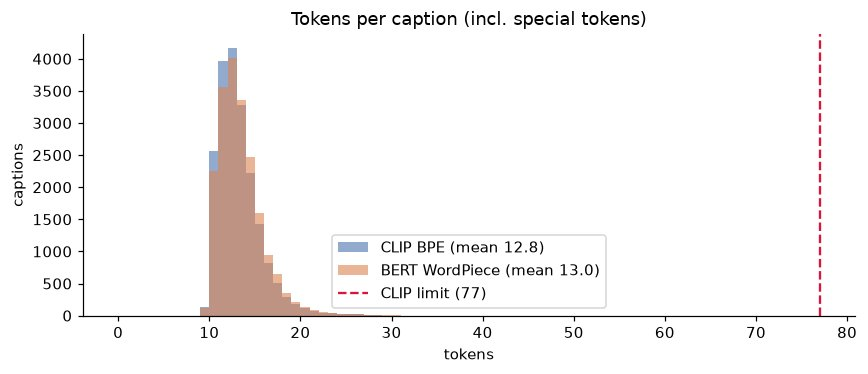

Longest caption: CLIP 30 tokens, BERT 32 tokens; captions truncated by CLIP: 0


In [3]:
clip_len = np.array([len(x) for x in clip_tok(caps.caption.tolist())["input_ids"]])
bert_len = np.array([len(x) for x in bert_tok(caps.caption.tolist())["input_ids"]])

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.arange(0, max(clip_len.max(), bert_len.max()) + 2)
ax.hist(clip_len, bins=bins, alpha=0.6, label=f"CLIP BPE (mean {clip_len.mean():.1f})", color="#4C72B0")
ax.hist(bert_len, bins=bins, alpha=0.6, label=f"BERT WordPiece (mean {bert_len.mean():.1f})", color="#DD8452")
ax.axvline(MAX_LEN, color="crimson", ls="--", label="CLIP limit (77)")
ax.set(title="Tokens per caption (incl. special tokens)", xlabel="tokens", ylabel="captions"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Longest caption: CLIP {clip_len.max()} tokens, BERT {bert_len.max()} tokens; "
      f"captions truncated by CLIP: {(clip_len > MAX_LEN).sum()}")

## 2. CLIP text embeddings

We call the text tower **the same way Stable Diffusion v1.5's pipeline does**: `max_length` padding to 77 and
**no attention mask**. CLIP's text Transformer uses causal attention, so the real tokens never see the padding,
and SD was trained with every one of the 77 output positions, padding included. Notebook 03 checks that these
tensors match SD's own `encode_prompt` exactly.

* `last_hidden_state` → `[B, 77, 768]`: the conditioning tensor. Kept for the 4,000 primary captions (float16, ~470 MB).
* `text_projection(pooler_output)` → `[B, 768]`: the joint text–image vector. Kept for **all** captions.

In transformers 5.x, `get_text_features()` returns an output object rather than a tensor, so we call
`text_model` and `text_projection` explicitly. That works the same on every version.

In [4]:
clip = CLIPModel.from_pretrained(CLIP_ID).eval().to(DEVICE)
print(f"CLIP ViT-L/14: {sum(p.numel() for p in clip.text_model.parameters()) / 1e6:.0f}M text params, "
      f"{sum(p.numel() for p in clip.vision_model.parameters()) / 1e6:.0f}M vision params, "
      f"projection dim {clip.config.projection_dim}")

@torch.no_grad()
def clip_encode_text(texts, keep_tokens=False, batch_size=TEXT_BATCH, desc="CLIP text"):
    # Returns (projected [N, 768] float32, per-token [N, 77, 768] float16 or None)
    pooled, tokens = [], []
    for i in tqdm(range(0, len(texts), batch_size), desc=desc, disable=len(texts) <= batch_size):
        ids = clip_tok(list(texts[i:i + batch_size]), padding="max_length", max_length=MAX_LEN,
                       truncation=True, return_tensors="pt").input_ids.to(DEVICE)
        out = clip.text_model(input_ids=ids)            # no attention mask - same as Stable Diffusion
        pooled.append(clip.text_projection(out.pooler_output).float().cpu())
        if keep_tokens:
            tokens.append(out.last_hidden_state.half().cpu())
    return torch.cat(pooled), (torch.cat(tokens) if keep_tokens else None)

timings = {}
t0 = time.perf_counter()
clip_txt, _ = clip_encode_text(caps.caption.tolist(), desc="CLIP pooled (all captions)")
timings["clip_text_all_s"] = time.perf_counter() - t0

primary = caps[caps.is_primary].reset_index(drop=True)
assert primary.caption_id.tolist() == pairs.sort_values("image_id").caption_id.tolist()
t0 = time.perf_counter()
_, clip_tokens = clip_encode_text(primary.caption.tolist(), keep_tokens=True, desc="CLIP per-token (pairs)")
timings["clip_tokens_pairs_s"] = time.perf_counter() - t0
_, uncond_tokens = clip_encode_text([""], keep_tokens=True)   # empty prompt, for classifier-free guidance

print(f"pooled      : {tuple(clip_txt.shape)} {clip_txt.dtype}  ({len(caps) / timings['clip_text_all_s']:.0f} captions/s on {DEVICE})")
print(f"per-token   : {tuple(clip_tokens.shape)} {clip_tokens.dtype}")
print(f"unconditional (\"\"): {tuple(uncond_tokens.shape)}")

CLIP ViT-L/14: 123M text params, 303M vision params, projection dim 768


CLIP pooled (all captions):   0%|          | 0/157 [00:00<?, ?it/s]

CLIP pooled (all captions):   1%|          | 1/157 [00:00<01:58,  1.32it/s]

CLIP pooled (all captions):   1%|▏         | 2/157 [00:01<01:46,  1.45it/s]

CLIP pooled (all captions):   2%|▏         | 3/157 [00:02<01:43,  1.49it/s]

CLIP pooled (all captions):   3%|▎         | 4/157 [00:02<01:41,  1.50it/s]

... (184 outputs left out)

CLIP per-token (pairs):  97%|█████████▋| 31/32 [00:19<00:00,  1.56it/s]

CLIP per-token (pairs): 100%|██████████| 32/32 [00:20<00:00,  2.01it/s]

CLIP per-token (pairs): 100%|██████████| 32/32 [00:20<00:00,  1.60it/s]

pooled      : (19977, 768) torch.float32  (199 captions/s on mps)
per-token   : (4000, 77, 768) torch.float16
unconditional (""): (1, 77, 768)


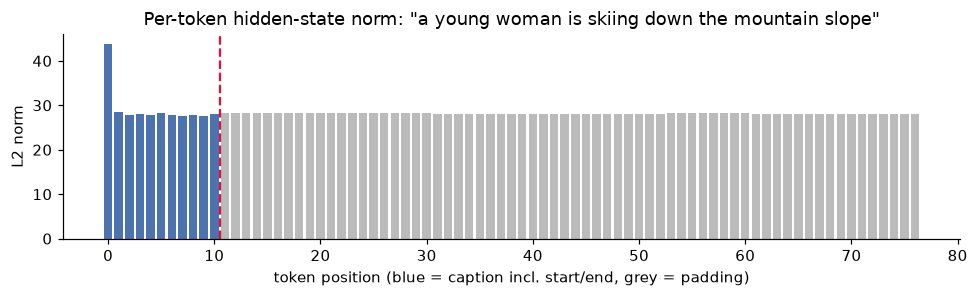

Padding positions are not zero: they carry a summary of the caption, and SD attends to all 77.


In [5]:
# What the 77 x 768 conditioning tensor looks like for one caption
i = 3
n_real = int((clip_tok(primary.caption[i]).input_ids.__len__()))
norms = clip_tokens[i].float().norm(dim=-1)
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.bar(range(MAX_LEN), norms, color=["#4C72B0" if p < n_real else "#BBBBBB" for p in range(MAX_LEN)])
ax.axvline(n_real - 0.5, color="crimson", ls="--")
ax.set(title=textwrap.shorten(f'Per-token hidden-state norm: "{primary.caption[i]}"', 95),
       xlabel="token position (blue = caption incl. start/end, grey = padding)", ylabel="L2 norm")
plt.tight_layout(); plt.show()
print("Padding positions are not zero: they carry a summary of the caption, and SD attends to all 77.")

## 3. CLIP image embeddings
CLIP's vision tower maps each processed image into the **same** 768-d space as the projected text vectors.
That lets us test the text embeddings against the images they should describe (Section 5). CLIP's own
processor resizes our 512×512 images to 224×224 and normalizes them.

In [6]:
img_proc = CLIPImageProcessor.from_pretrained(CLIP_ID)

@torch.no_grad()
def clip_encode_images(paths, batch_size=IMAGE_BATCH):
    feats = []
    for i in tqdm(range(0, len(paths), batch_size), desc="CLIP images"):
        batch = [Image.open(ROOT / p).convert("RGB") for p in paths[i:i + batch_size]]
        px = img_proc(images=batch, return_tensors="pt").pixel_values.to(DEVICE)
        feats.append(clip.visual_projection(clip.vision_model(pixel_values=px).pooler_output).float().cpu())
    return torch.cat(feats)

img_order = pairs.sort_values("image_id").reset_index(drop=True)      # same order as `primary`
t0 = time.perf_counter()
clip_img = clip_encode_images(img_order.image_path.tolist())
timings["clip_images_s"] = time.perf_counter() - t0
print(f"image embeddings: {tuple(clip_img.shape)}  ({len(img_order) / timings['clip_images_s']:.0f} images/s)")

CLIP images:   0%|          | 0/125 [00:00<?, ?it/s]

CLIP images:   1%|          | 1/125 [00:02<04:21,  2.11s/it]

CLIP images:   2%|▏         | 2/125 [00:04<04:15,  2.08s/it]

CLIP images:   2%|▏         | 3/125 [00:06<04:12,  2.07s/it]

CLIP images:   3%|▎         | 4/125 [00:08<04:09,  2.07s/it]

CLIP images:   4%|▍         | 5/125 [00:10<04:07,  2.07s/it]

... (118 outputs left out)

CLIP images:  99%|█████████▉| 124/125 [04:16<00:02,  2.06s/it]

CLIP images: 100%|██████████| 125/125 [04:18<00:00,  2.06s/it]

CLIP images: 100%|██████████| 125/125 [04:18<00:00,  2.07s/it]

image embeddings: (4000, 768)  (15 images/s)


## 4. BERT text embeddings
BERT has no special sentence vector trained for similarity, so we take two common choices:
**mean pooling** over the real tokens (padding masked out) and the **`[CLS]`** token's state.

In [7]:
bert = AutoModel.from_pretrained(BERT_ID).eval().to(DEVICE)
print(f"BERT-base: {sum(p.numel() for p in bert.parameters()) / 1e6:.0f}M params, hidden size {bert.config.hidden_size}")

@torch.no_grad()
def bert_encode(texts, batch_size=TEXT_BATCH):
    mean, cls = [], []
    for i in tqdm(range(0, len(texts), batch_size), desc="BERT"):
        enc = bert_tok(list(texts[i:i + batch_size]), padding=True, truncation=True,
                       max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
        h = bert(**enc).last_hidden_state
        m = enc.attention_mask.unsqueeze(-1).to(h.dtype)
        mean.append(((h * m).sum(1) / m.sum(1)).float().cpu())
        cls.append(h[:, 0].float().cpu())
    return torch.cat(mean), torch.cat(cls)

t0 = time.perf_counter()
bert_mean, bert_cls = bert_encode(caps.caption.tolist())
timings["bert_all_s"] = time.perf_counter() - t0
print(f"mean-pooled: {tuple(bert_mean.shape)} · [CLS]: {tuple(bert_cls.shape)}  "
      f"({len(caps) / timings['bert_all_s']:.0f} captions/s)")

BERT-base: 109M params, hidden size 768


BERT:   0%|          | 0/157 [00:00<?, ?it/s]

BERT:   1%|          | 1/157 [00:00<00:38,  4.03it/s]

BERT:   1%|▏         | 2/157 [00:00<00:35,  4.31it/s]

BERT:   2%|▏         | 3/157 [00:00<00:36,  4.23it/s]

BERT:   3%|▎         | 4/157 [00:00<00:34,  4.43it/s]

... (150 outputs left out)

BERT:  99%|█████████▊| 155/157 [00:27<00:00,  5.77it/s]

BERT:  99%|█████████▉| 156/157 [00:27<00:00,  5.34it/s]

BERT: 100%|██████████| 157/157 [00:27<00:00,  5.72it/s]

mean-pooled: (19977, 768) · [CLS]: (19977, 768)  (728 captions/s)


## 5. Sanity checks

### 5.1 Shapes and numerical health

In [8]:
text_spaces = {"CLIP (projected)": clip_txt, "BERT mean-pool": bert_mean, "BERT [CLS]": bert_cls}
all_tensors = {**text_spaces, "CLIP per-token": clip_tokens, "CLIP image": clip_img}
health = pd.DataFrame({
    name: {"shape": tuple(t.shape), "dtype": str(t.dtype).replace("torch.", ""),
           "finite": bool(torch.isfinite(t.float()).all()),
           "mean L2 norm": round(float(t.float().norm(dim=-1).mean()), 2)}
    for name, t in all_tensors.items()
}).T
assert health.finite.all()
assert clip_txt.shape == (len(caps), 768) and clip_tokens.shape == (len(pairs), MAX_LEN, 768)
health

,shape,dtype,finite,mean L2 norm
CLIP (projected),"(19977, 768)",float32,True,13.35
BERT mean-pool,"(19977, 768)",float32,True,9.74
BERT [CLS],"(19977, 768)",float32,True,14.55
CLIP per-token,"(4000, 77, 768)",float16,True,28.23
CLIP image,"(4000, 768)",float32,True,18.63


### 5.2 Do captions of the same image sit closer together?
Every image has ~5 captions written by different people. A good sentence embedding should give
**same-image caption pairs** a higher cosine similarity than random **different-image pairs**.
We measure how well the similarity separates the two groups with ROC-AUC (1.0 = perfect, 0.5 = chance).

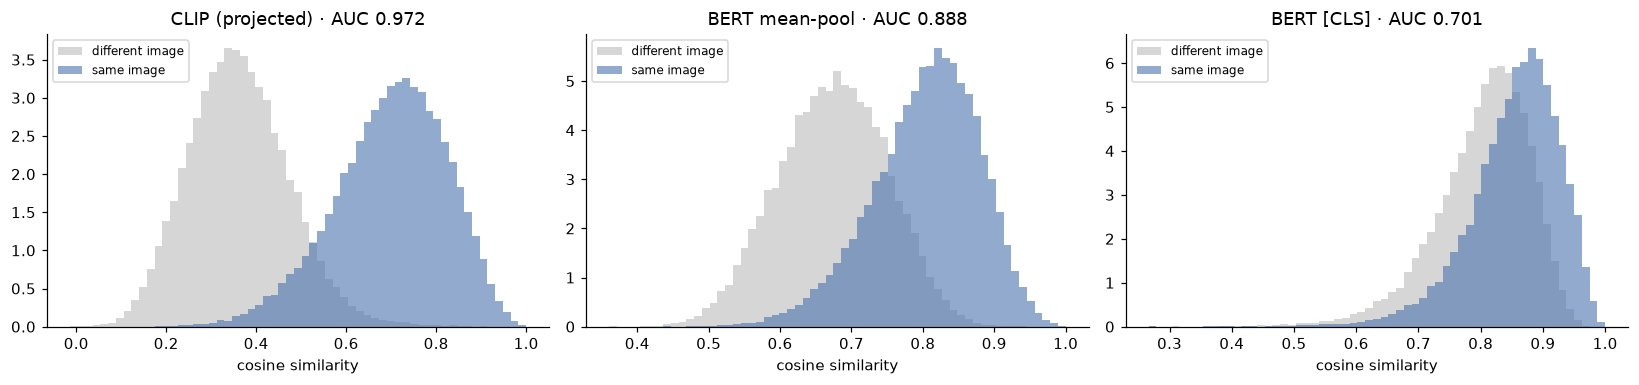

39,921 same-image pairs vs 39,921 different-image pairs


,same-image mean cos,different-image mean cos,gap,ROC-AUC
CLIP (projected),0.699,0.361,0.338,0.972
BERT mean-pool,0.804,0.673,0.131,0.888
BERT [CLS],0.854,0.803,0.051,0.701


In [9]:
pos = np.array([p for idx in caps.groupby("image_id").indices.values()
                  for p in itertools.combinations(idx, 2)])
rng = np.random.default_rng(SEED)
neg = rng.integers(0, len(caps), size=(len(pos) * 2, 2))
neg = neg[caps.image_id.values[neg[:, 0]] != caps.image_id.values[neg[:, 1]]][: len(pos)]

def pair_cos(E, idx):
    E = F.normalize(E.float(), dim=-1)
    return (E[idx[:, 0]] * E[idx[:, 1]]).sum(-1).numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
separation = {}
for ax, (name, E) in zip(axes, text_spaces.items()):
    sp, sn = pair_cos(E, pos), pair_cos(E, neg)
    auc = roc_auc_score(np.r_[np.ones(len(sp)), np.zeros(len(sn))], np.r_[sp, sn])
    separation[name] = {"same-image mean cos": sp.mean(), "different-image mean cos": sn.mean(),
                        "gap": sp.mean() - sn.mean(), "ROC-AUC": auc}
    bins = np.linspace(min(sp.min(), sn.min()), 1, 60)
    ax.hist(sn, bins=bins, alpha=0.6, density=True, label="different image", color="#BBBBBB")
    ax.hist(sp, bins=bins, alpha=0.6, density=True, label="same image", color="#4C72B0")
    ax.set(title=f"{name} · AUC {auc:.3f}", xlabel="cosine similarity"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "02_same_vs_different_image.png", bbox_inches="tight"); plt.show()
print(f"{len(pos):,} same-image pairs vs {len(neg):,} different-image pairs")
pd.DataFrame(separation).T.round(3)

### 5.3 Caption → caption retrieval (CLIP vs BERT)
This is a text-only test, so both encoders can be compared on equal terms. Each of the 4,000 primary captions
queries the other ~20k captions. A hit at K means one of the top-K neighbours is **another caption of the same image**.

In [10]:
@torch.no_grad()
def caption_to_caption_recall(E, ks=KS, chunk=1024):
    E = F.normalize(E.float(), dim=-1).to(DEVICE)
    img = torch.as_tensor(caps.image_id.values, device=DEVICE)
    queries = torch.as_tensor(np.flatnonzero(caps.is_primary.values), device=DEVICE)
    hits = dict.fromkeys(ks, 0)
    for q in queries.split(chunk):
        s = E[q] @ E.T
        s[torch.arange(len(q), device=DEVICE), q] = -float("inf")       # don't retrieve the query itself
        same = img[s.topk(max(ks), dim=1).indices] == img[q, None]
        for k in ks:
            hits[k] += int(same[:, :k].any(1).sum())
    return {f"R@{k}": hits[k] / len(queries) for k in ks}

c2c = pd.DataFrame({name: caption_to_caption_recall(E) for name, E in text_spaces.items()}).T
c2c.style.format("{:.1%}")

,R@1,R@5,R@10
CLIP (projected),37.0%,57.9%,67.4%
BERT mean-pool,16.9%,32.3%,39.8%
BERT [CLS],6.9%,13.5%,17.5%


### 5.4 Text ↔ image retrieval (CLIP)
This is the most direct test of the pipeline: does a caption's embedding point at **its own image**?
We follow the standard COCO protocol, with ~5 captions per image:

* **text → image:** each caption ranks all images; a hit is its own image in the top K.
* **image → text:** each image ranks all captions; a hit is any of its own captions in the top K.

It's reported for the full 4,000-image subset and for the 400-image **test split**. For reference, the CLIP
paper reports roughly 58% (image→text) and 38% (text→image) R@1 zero-shot on the 5k COCO test set
for its largest model. A smaller gallery is easier, so our numbers should be in that range or a bit above.

In [11]:
@torch.no_grad()
def cross_modal_recall(T, t_img, I, i_img, ks=KS):
    T = F.normalize(T.float(), dim=-1).to(DEVICE); I = F.normalize(I.float(), dim=-1).to(DEVICE)
    t_img = torch.as_tensor(t_img, device=DEVICE); i_img = torch.as_tensor(i_img, device=DEVICE)
    s = T @ I.T                                                            # [captions, images]
    t2i = i_img[s.topk(max(ks), dim=1).indices] == t_img[:, None]          # caption -> its image
    i2t = t_img[s.T.topk(max(ks), dim=1).indices] == i_img[:, None]        # image -> any of its captions
    out = {}
    for k in ks:
        out[f"text→image R@{k}"] = float(t2i[:, :k].any(1).float().mean())
    for k in ks:
        out[f"image→text R@{k}"] = float(i2t[:, :k].any(1).float().mean())
    return out

img_ids = img_order.image_id.values
retrieval = {}
for split_name, img_mask in [("all 4,000 images", np.ones(len(img_ids), bool)),
                             ("test split (400)", (img_order.split == "test").values)]:
    cap_mask = caps.image_id.isin(img_ids[img_mask]).values
    retrieval[split_name] = cross_modal_recall(clip_txt[cap_mask], caps.image_id.values[cap_mask],
                                               clip_img[img_mask], img_ids[img_mask])
retrieval = pd.DataFrame(retrieval).T
retrieval.style.format("{:.1%}")

,text→image R@1,text→image R@5,text→image R@10,image→text R@1,image→text R@5,image→text R@10
"all 4,000 images",38.0%,63.4%,73.4%,58.7%,81.5%,88.6%
test split (400),64.5%,92.2%,97.3%,80.8%,97.5%,99.3%


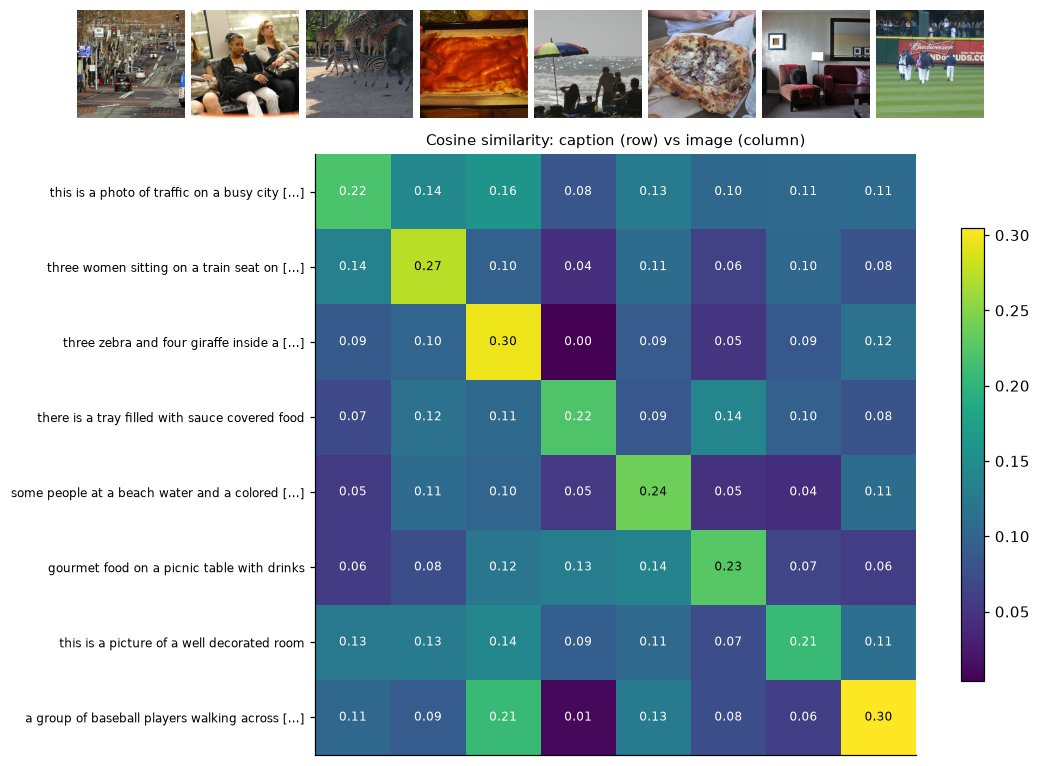

Diagonal is the row maximum for 8 of 8 captions


In [12]:
# CLIP similarity matrix: 8 test images vs their primary captions (the diagonal should be brightest)
demo = img_order[img_order.split == "test"].sample(8, random_state=SEED)
pos_idx = demo.index.values
S = (F.normalize(clip_txt[caps.is_primary.values][pos_idx], dim=-1) @ F.normalize(clip_img[pos_idx], dim=-1).T).numpy()

fig = plt.figure(figsize=(14, 9))
grid = fig.add_gridspec(2, 9, height_ratios=[1, 4.2], width_ratios=[2.6] + [1] * 8, hspace=0.05, wspace=0.05)
for j, row in enumerate(demo.itertuples()):
    ax = fig.add_subplot(grid[0, j + 1]); ax.imshow(Image.open(ROOT / row.image_path)); ax.axis("off")
ax = fig.add_subplot(grid[1, 1:])
im = ax.imshow(S, cmap="viridis")
for (r, c), v in np.ndenumerate(S):
    ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v < S.max() - 0.08 else "black")
ax.set_xticks([]); ax.set_yticks(range(len(demo)))
ax.set_yticklabels([textwrap.shorten(c, 48) for c in demo.caption], fontsize=8)
ax.set_title("Cosine similarity: caption (row) vs image (column)", fontsize=10)
fig.colorbar(im, ax=ax, fraction=0.025)
fig.savefig(FIG_DIR / "02_clip_similarity_matrix.png", bbox_inches="tight"); plt.show()
print(f"Diagonal is the row maximum for {(S.argmax(1) == np.arange(len(S))).sum()} of {len(S)} captions")

### 5.5 Nearest neighbours (qualitative)
For a few captions: the closest captions from **other** images in each space. CLIP should match on visual
content (objects, scene). BERT is more prone to matching on sentence form.

In [13]:
def neighbours(E, q, k=3):
    E = F.normalize(E.float(), dim=-1)
    s = E @ E[q]
    s[torch.as_tensor(caps.image_id.values == caps.image_id.values[q])] = -1   # exclude the query's own image
    return [(caps.caption[j], float(s[j])) for j in s.topk(k).indices.tolist()]

for q in caps.index[caps.is_primary].to_series().sample(3, random_state=SEED):
    print(f"QUERY: {caps.caption[q]}")
    for name in ("CLIP (projected)", "BERT mean-pool"):
        print(f"  {name}")
        for text, s in neighbours(text_spaces[name], q):
            print(f"     {s:.3f}  {textwrap.shorten(text, 90)}")
    print()

QUERY: a small truck parked on the side of a street ready to go
  CLIP (projected)
     0.828  a truck loaded with cargo slowly creeps down the street
     0.801  a brightly painted truck on a city street
     0.799  a garbage truck on the street next to a building
  BERT mean-pool
     0.918  a row of parked motorcycle sitting on the side of a road
     0.913  small automobile parked on the side of a beach area
     0.899  a bus parked on the side of the road next to a bike

QUERY: a street sign displaying that vehicles will be towed
  CLIP (projected)
     0.799  a street sign prohibiting vehicles in front of a store
     0.749  road signage with sticker displayed near parking area
     0.743  a red sign notifying drivers that there is no parking allowed at any time
  BERT mean-pool
     0.872  a red sign notifying drivers that there is no parking allowed at any time
     0.869  a street sign prohibiting vehicles in front of a store
     0.867  a red sign letting drivers know to stop

### 5.6 Embedding space structure (t-SNE)
Primary-caption embeddings projected to 2-D and coloured by the image's COCO supercategory (from notebook 01).
Clear clusters mean the embedding captures *what is in the scene*.

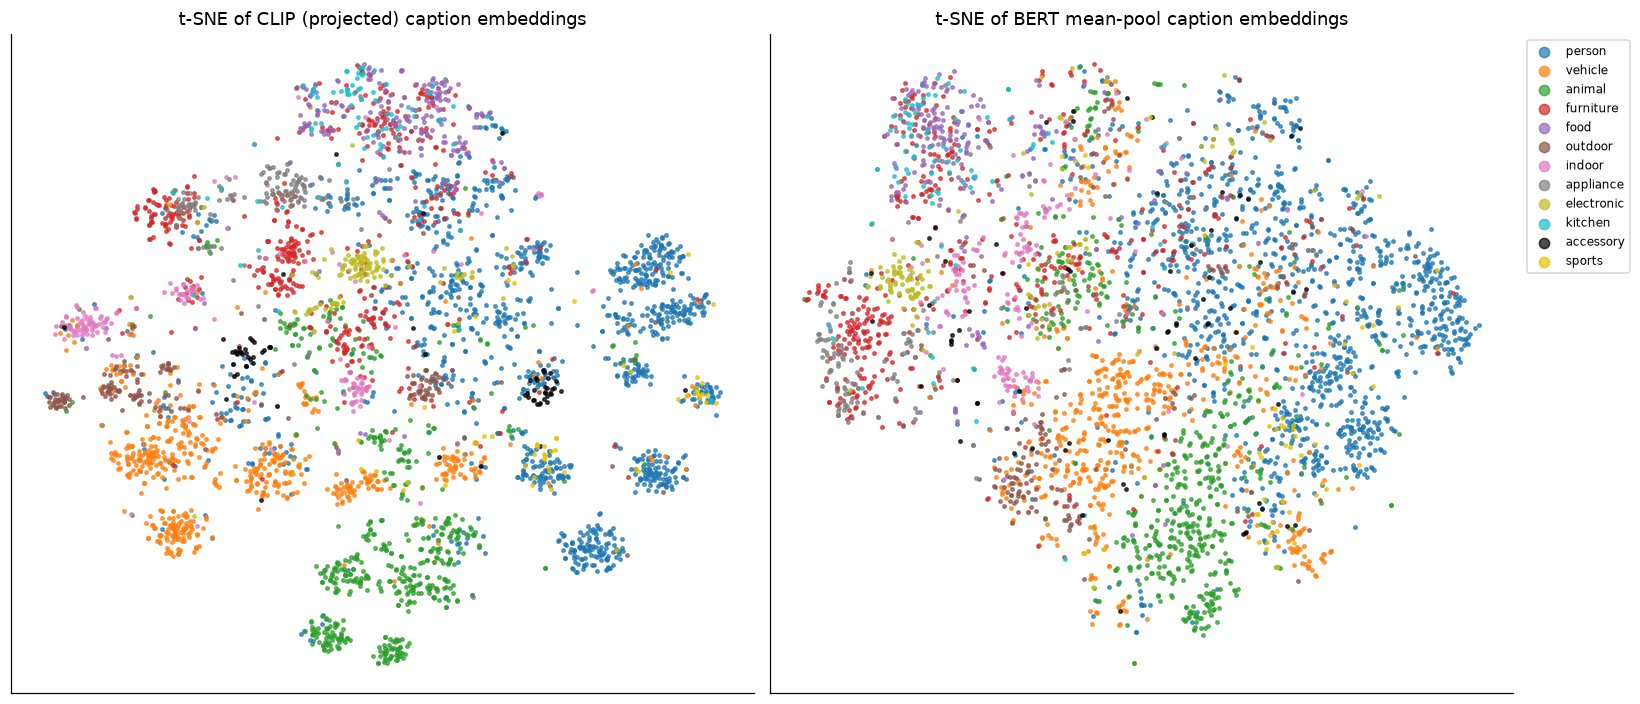

In [14]:
mask = (primary.image_id.map(pairs.set_index("image_id").supercategory) != "none").values
labels = primary.image_id.map(pairs.set_index("image_id").supercategory).values[mask]
cats = pd.Series(labels).value_counts().index
colors = dict(zip(cats, list(plt.cm.tab10.colors) + ["#000000", "#E6C200"]))   # 12 distinct colours

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (name, E) in zip(axes, [("CLIP (projected)", clip_txt), ("BERT mean-pool", bert_mean)]):
    X = F.normalize(E[caps.is_primary.values].float(), dim=-1).numpy()[mask]
    Y = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(X)
    for c in cats:
        m = labels == c
        ax.scatter(Y[m, 0], Y[m, 1], s=5, alpha=0.7, color=colors[c], label=c)
    ax.set(title=f"t-SNE of {name} caption embeddings"); ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(markerscale=3, fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout(); fig.savefig(FIG_DIR / "02_tsne.png", bbox_inches="tight"); plt.show()

## 6. Save the embeddings

In [15]:
meta = {"clip_model": CLIP_ID, "bert_model": BERT_ID, "max_length": MAX_LEN,
        "note": "vectors are NOT L2-normalized; normalize before cosine similarity"}
torch.save({"caption_id": torch.as_tensor(caps.caption_id.values), "image_id": torch.as_tensor(caps.image_id.values),
            "emb": clip_txt, **meta}, EMB_DIR / "clip_text_pooled.pt")
torch.save({"caption_id": torch.as_tensor(primary.caption_id.values), "image_id": torch.as_tensor(primary.image_id.values),
            "emb": clip_tokens, "uncond": uncond_tokens, **meta,
            "encoding": "CLIPTokenizer max_length=77 padding, text_model without attention mask (as SD v1.5)"},
           EMB_DIR / "clip_text_tokens.pt")
torch.save({"image_id": torch.as_tensor(img_ids), "emb": clip_img, **meta}, EMB_DIR / "clip_image.pt")
torch.save({"caption_id": torch.as_tensor(caps.caption_id.values), "image_id": torch.as_tensor(caps.image_id.values),
            "mean": bert_mean, "cls": bert_cls, **meta}, EMB_DIR / "bert_text.pt")

report = {
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "device": DEVICE, "timings_s": {k: round(v, 1) for k, v in timings.items()},
    "shapes": {k: list(v.shape) for k, v in all_tensors.items()},
    "same_vs_different_image": {k: {m: round(float(x), 4) for m, x in v.items()} for k, v in separation.items()},
    "caption_to_caption_recall": c2c.round(4).to_dict(orient="index"),
    "clip_text_image_recall": retrieval.round(4).to_dict(orient="index"),
    "versions": {"python": sys.version.split()[0], "torch": torch.__version__,
                 "transformers": transformers.__version__, "scikit-learn": sklearn.__version__},
}
(EMB_DIR / "embedding_report.json").write_text(json.dumps(report, indent=2))
for p in sorted(EMB_DIR.iterdir()):
    print(f"{p.relative_to(ROOT).as_posix():50s} {p.stat().st_size / 1e6:8.1f} MB")

data/processed/embeddings/bert_text.pt                123.1 MB
data/processed/embeddings/clip_image.pt                12.3 MB
data/processed/embeddings/clip_text_pooled.pt          61.7 MB
data/processed/embeddings/clip_text_tokens.pt         473.3 MB
data/processed/embeddings/embedding_report.json         0.0 MB


In [16]:
# Reload and verify alignment with the parquet files
r = torch.load(EMB_DIR / "clip_text_tokens.pt")
assert r["caption_id"].tolist() == pairs.sort_values("image_id").caption_id.tolist()
assert r["emb"].shape == (len(pairs), MAX_LEN, 768) and r["uncond"].shape == (1, MAX_LEN, 768)
r = torch.load(EMB_DIR / "clip_text_pooled.pt")
assert r["caption_id"].tolist() == caps.caption_id.tolist()
r = torch.load(EMB_DIR / "clip_image.pt")
assert r["image_id"].tolist() == pairs.sort_values("image_id").image_id.tolist()
r = torch.load(EMB_DIR / "bert_text.pt")
assert r["mean"].shape == r["cls"].shape == (len(caps), 768)
print("All embedding files reload correctly and are aligned with pairs.parquet / captions.parquet.")

All embedding files reload correctly and are aligned with pairs.parquet / captions.parquet.


## Summary
| Check | CLIP ViT-L/14 | BERT mean-pool | BERT `[CLS]` |
|---|---|---|---|
| Same- vs different-image caption separation (ROC-AUC) | **0.972** | 0.888 | 0.701 |
| Caption → caption R@1 / R@10 | **37.0% / 67.4%** | 16.9% / 39.8% | 6.9% / 17.5% |
| Text → image R@1 / R@5 (4,000 images) | **38.0% / 63.4%** | n/a | n/a |
| Image → text R@1 / R@5 (4,000 images) | **58.7% / 81.5%** | n/a | n/a |

*(Exact values are in the tables above and in `embedding_report.json`.)*

**What these results show**

1. **The text → embedding pipeline is correct.** Zero-shot text→image R@1 of 38% and image→text R@1 of 59% on our
   4,000-image subset match what the CLIP paper reports on the 5k COCO test set (about 38% / 58%). The tokenization,
   encoding, projection and image preprocessing all behave as expected. On the 400-image test split, the scores
   rise to 64.5% / 80.8% because the gallery is 10× smaller.
2. **CLIP captures visual content, BERT captures sentence form.** CLIP separates same-image from different-image captions
   far better (AUC 0.97 vs 0.89) and retrieves captions of the same image over twice as often. The nearest-neighbour
   examples show why: for *"a small truck parked on the side of a street"*, CLIP returns other trucks, while BERT returns
   *"a row of parked motorcycles…"* and *"a bus parked on the side of the road…"*, which share the phrasing but not the
   object. The t-SNE plot shows the same pattern: CLIP forms clear category clusters.
3. **BERT's similarities are compressed.** Even unrelated captions have cosine around 0.67 (mean-pool) and 0.80 (`[CLS]`).
   This is the known anisotropy of raw BERT embeddings, and the reason `[CLS]` without fine-tuning is a poor sentence
   vector. Mean pooling is clearly the better BERT baseline.
4. **The conditioning tensors are ready for generation.** All 4,000 primary captions have their `[77, 768]` CLIP
   hidden states saved, encoded exactly as Stable Diffusion v1.5 does, along with the empty-prompt embedding needed for
   classifier-free guidance. BERT is **not** a drop-in replacement: SD's cross-attention layers were trained on CLIP-L's
   space, so BERT conditioning would need a trained adapter. It stays a comparison baseline.

**Saved to `data/processed/embeddings/`:** `clip_text_tokens.pt` (conditioning + unconditional), `clip_text_pooled.pt`,
`clip_image.pt`, `bert_text.pt`, `embedding_report.json`.

**Next, notebook `03_baseline_generation`:** feed these embeddings to Stable Diffusion v1.5 and generate the 5 sample
prompt → image runs.